Khai báo thư viện

In [26]:
print("NguyenDucTinh - 6451071077")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.naive_bayes import CategoricalNB
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.preprocessing import OrdinalEncoder

NguyenDucTinh - 6451071077


Nạp dữ liệu Phân tích cảm xúc (14 mẫu)

In [27]:
print("NguyenDucTinh - 6451071077")

data_sentiment = {
    'giảm': ['0..5', '11..20', '6..10', '>20', '0..5', '0..5', '0..5', '11..20', '0..5', '11..20', '>20', '0..5', '6..10', '11..20'],
    'người': ['11..20', '6..10', '0..5', '0..5', '>20', '6..10', '6..10', '>20', '0..5', '0..5', '6..10', '0..5', '11..20', '6..10'],
    'chuyển': ['>20', '6..10', '6..10', '11..20', '11..20', '0..5', '11..20', '0..5', '6..10', '11..20', '0..5', '11..20', '6..10', '>20'],
    'yêu': ['11..20', '0..5', '11..20', '6..10', '0..5', '0..5', '0..5', '11..20', '6..10', '11..20', '0..5', '0..5', '>20', '11..20'],
    'vừa': ['>20', '11..20', '0..5', '0..5', '6..10', '11..20', '6..10', '0..5', '6..10', '0..5', '0..5', '11..20', '0..5', '0..5'],
    'đi': ['0..5', '11..20', '6..10', '>20', '0..5', '11..20', '0..5', '11..20', '>20', '11..20', '6..10', '>20', '6..10', '0..5'],
    'Cảm xúc': ['tốt', 'tốt', 'xấu', 'bình thường', 'xấu', 'xấu', 'tốt', 'bình thường', 'tốt', 'tốt', 'xấu', 'bình thường', 'bình thường', 'xấu']
}

df_sent = pd.DataFrame(data_sentiment)
features_sent = ['giảm', 'người', 'chuyển', 'yêu', 'vừa', 'đi']

encoder_sent = OrdinalEncoder()
X_sent_enc = encoder_sent.fit_transform(df_sent[features_sent])
y_sent = df_sent['Cảm xúc']

display(df_sent)

NguyenDucTinh - 6451071077


,giảm,người,chuyển,yêu,vừa,đi,Cảm xúc
0,0..5,11..20,>20,11..20,>20,0..5,tốt
1,11..20,6..10,6..10,0..5,11..20,11..20,tốt
2,6..10,0..5,6..10,11..20,0..5,6..10,xấu
3,>20,0..5,11..20,6..10,0..5,>20,bình thường
4,0..5,>20,11..20,0..5,6..10,0..5,xấu
5,0..5,6..10,0..5,0..5,11..20,11..20,xấu
6,0..5,6..10,11..20,0..5,6..10,0..5,tốt
7,11..20,>20,0..5,11..20,0..5,11..20,bình thường
8,0..5,0..5,6..10,6..10,6..10,>20,tốt
9,11..20,0..5,11..20,11..20,0..5,11..20,tốt


a - Kiểm tra mâu thuẫn dữ liệu

In [28]:
print("NguyenDucTinh - 6451071077")

print("CÂU a: XÁC ĐỊNH MÂU THUẪN TRONG DỮ LIỆU")
duplicates_sent = df_sent[df_sent.duplicated(subset=features_sent, keep=False)]

if len(duplicates_sent) == 0:
    print("a) KẾT LUẬN: Tập dữ liệu phân tích cảm xúc HOÀN TOÀN KHÔNG CÓ MÂU THUẪN trực tiếp nào.")
else:
    print("a) Phát hiện các dòng mâu thuẫn:")
    display(duplicates_sent)

NguyenDucTinh - 6451071077
CÂU a: XÁC ĐỊNH MÂU THUẪN TRONG DỮ LIỆU
a) KẾT LUẬN: Tập dữ liệu phân tích cảm xúc HOÀN TOÀN KHÔNG CÓ MÂU THUẪN trực tiếp nào.


b - Tính chỉ số Gini (CART) và vẽ cây quyết định

NguyenDucTinh - 6451071077
CÂU b: TÍNH TOÁN CHI TIẾT CHỈ SỐ GINI VÀ VẼ CÂY QUYẾT ĐỊNH CART
Tổng số mẫu: 14
Phân phối nhãn Cảm xúc: {'tốt': np.int64(5), 'xấu': np.int64(5), 'bình thường': np.int64(4)}

-> Gini tổng thể Gini(S) = 1 - sum((p_i)^2) = 0.6633

--- Xét thuộc tính: 'giảm' ---
  + Giá trị '0..5' (6 mẫu) -> Gini = 0.6111
  + Giá trị '11..20' (4 mẫu) -> Gini = 0.6250
  + Giá trị '6..10' (2 mẫu) -> Gini = 0.5000
  + Giá trị '>20' (2 mẫu) -> Gini = 0.5000
  => Gini_weighted(S, giảm) = 0.5833 | Độ giảm Gini = 0.0799

--- Xét thuộc tính: 'người' ---
  + Giá trị '11..20' (2 mẫu) -> Gini = 0.5000
  + Giá trị '6..10' (5 mẫu) -> Gini = 0.4800
  + Giá trị '0..5' (5 mẫu) -> Gini = 0.6400
  + Giá trị '>20' (2 mẫu) -> Gini = 0.5000
  => Gini_weighted(S, người) = 0.5429 | Độ giảm Gini = 0.1204

--- Xét thuộc tính: 'chuyển' ---
  + Giá trị '>20' (2 mẫu) -> Gini = 0.5000
  + Giá trị '6..10' (4 mẫu) -> Gini = 0.6250
  + Giá trị '11..20' (5 mẫu) -> Gini = 0.6400
  + Giá trị '0..5' (3 mẫu) -> Gini

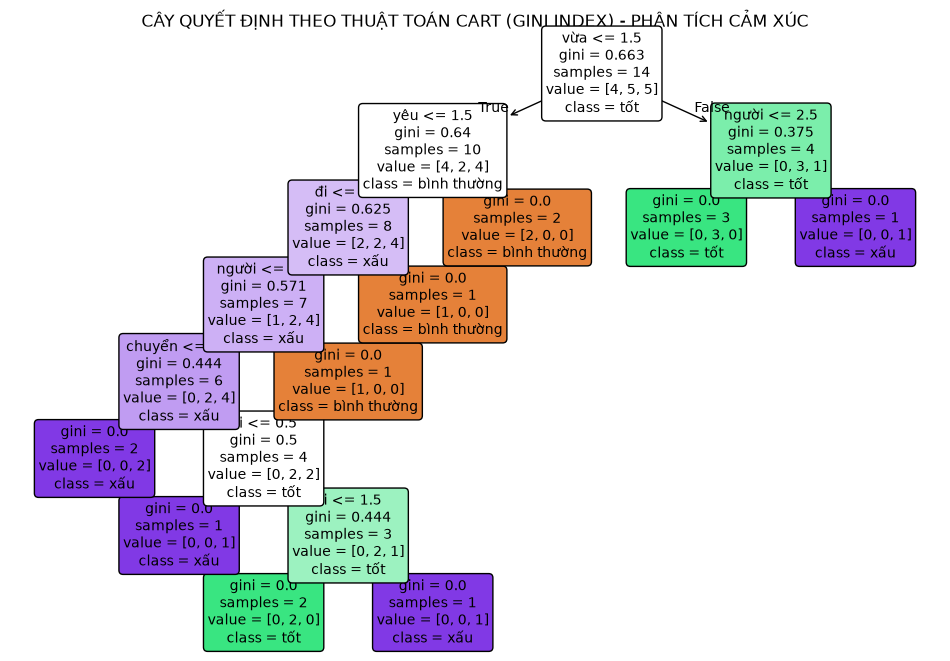

In [29]:
print("NguyenDucTinh - 6451071077")

print("CÂU b: TÍNH TOÁN CHI TIẾT CHỈ SỐ GINI VÀ VẼ CÂY QUYẾT ĐỊNH CART")

# 1. Tính Gini tổng thể Gini(S)
total_samples = len(df_sent)
class_counts = df_sent['Cảm xúc'].value_counts()
print(f"Tổng số mẫu: {total_samples}")
print(f"Phân phối nhãn Cảm xúc: {dict(class_counts)}")

# Gini(S) = 1 - sum((p_i)^2)
gini_S = 1 - sum((counts / total_samples) ** 2 for counts in class_counts.values)
print(f"\n-> Gini tổng thể Gini(S) = 1 - sum((p_i)^2) = {gini_S:.4f}\n")

# Hàm tính Gini cho một tập con
def calc_gini(sub_df):
    tot = len(sub_df)
    if tot == 0: 
        return 0
    counts = sub_df['Cảm xúc'].value_counts()
    return 1 - sum((c / tot) ** 2 for c in counts.values)

# 2. Tính Gini Index cho từng thuộc tính (từ khóa)
ginis = {}
for attr in features_sent:
    gini_attr = 0
    print(f"--- Xét thuộc tính: '{attr}' ---")
    for val in df_sent[attr].unique():
        sub = df_sent[df_sent[attr] == val]
        g = calc_gini(sub)
        weight = len(sub) / total_samples
        gini_attr += weight * g
        print(f"  + Giá trị '{val}' ({len(sub)} mẫu) -> Gini = {g:.4f}")
    
    # Độ giảm Gini (Gini Index reduction)
    delta_gini = gini_S - gini_attr
    ginis[attr] = delta_gini
    print(f"  => Gini_weighted(S, {attr}) = {gini_attr:.4f} | Độ giảm Gini = {delta_gini:.4f}\n")

best_cart_attr = max(ginis, key=ginis.get)
print(f"===> Thuộc tính phân tách tốt nhất (độ giảm Gini lớn nhất): '{best_cart_attr}'\n")

# 3. Huấn luyện và vẽ cây quyết định CART
clf_cart_sent = DecisionTreeClassifier(criterion='gini', random_state=42)
clf_cart_sent.fit(X_sent_enc, y_sent)

plt.figure(figsize=(12, 8))
plot_tree(clf_cart_sent, 
          feature_names=features_sent, 
          class_names=clf_cart_sent.classes_, 
          filled=True, 
          rounded=True, 
          fontsize=10)
plt.title("CÂY QUYẾT ĐỊNH THEO THUẬT TOÁN CART (GINI INDEX) - PHÂN TÍCH CẢM XÚC")
plt.show()

c - Dự đoán cảm xúc bằng Cây quyết định và Naïve Bayes

In [30]:
print("NguyenDucTinh - 6451071077")

print("CÂU c: DỰ ĐOÁN CẢM XÚC BẰNG CÂY QUYẾT ĐỊNH VÀ NAÏVE BAYES")

# 4 trạng thái cần dự đoán
test_sent = pd.DataFrame({
    'giảm': ['0..5', '0..5', '6..10', '6..10'],
    'người': ['6..10', '0..5', '0..5', '11..20'],
    'chuyển': ['0..5', '6..10', '11..20', '6..10'],
    'yêu': ['11..20', '0..5', '>20', '6..10'],
    'vừa': ['6..10', '11..20', '6..10', '>20'],
    'đi': ['0..5', '>20', '6..10', '0..5']
})

X_test_sent_enc = encoder_sent.transform(test_sent)

# 1. Dự đoán bằng Cây quyết định (CART)
y_pred_cart = clf_cart_sent.predict(X_test_sent_enc)

# 2. Dự đoán bằng Naïve Bayes (Laplace smoothing)
clf_nb_sent = CategoricalNB(alpha=1.0)
clf_nb_sent.fit(X_sent_enc, y_sent)
y_pred_nb_sent = clf_nb_sent.predict(X_test_sent_enc)

print("Kết quả dự đoán:")
for i in range(len(test_sent)):
    print(f"Trạng thái {i+1} -> CART: {y_pred_cart[i]} | Naïve Bayes: {y_pred_nb_sent[i]}")

NguyenDucTinh - 6451071077
CÂU c: DỰ ĐOÁN CẢM XÚC BẰNG CÂY QUYẾT ĐỊNH VÀ NAÏVE BAYES
Kết quả dự đoán:
Trạng thái 1 -> CART: tốt | Naïve Bayes: xấu
Trạng thái 2 -> CART: bình thường | Naïve Bayes: tốt
Trạng thái 3 -> CART: tốt | Naïve Bayes: bình thường
Trạng thái 4 -> CART: tốt | Naïve Bayes: tốt


d - Lập ma trận nhầm lẫn, tính Precision, Recall và So sánh

In [31]:
print("NguyenDucTinh - 6451071077")

print("CÂU d: ĐÁNH GIÁ VÀ SO SÁNH HAI MÔ HÌNH")
y_true_sent = ['xấu', 'tốt', 'bình thường', 'tốt']
labels_list = ['tốt', 'xấu', 'bình thường']

print("--- 1. Mô hình Cây quyết định (CART) ---")
cm_cart = confusion_matrix(y_true_sent, y_pred_cart, labels=labels_list)
print("Ma trận nhầm lẫn:")
print(pd.DataFrame(cm_cart, index=[f"Thực tế {l}" for l in labels_list], columns=[f"Dự đoán {l}" for l in labels_list]))
print("\nBáo cáo chi tiết:")
print(classification_report(y_true_sent, y_pred_cart, labels=labels_list, zero_division=0))

print("\n--- 2. Mô hình Naïve Bayes ---")
cm_nb_sent = confusion_matrix(y_true_sent, y_pred_nb_sent, labels=labels_list)
print("Ma trận nhầm lẫn:")
print(pd.DataFrame(cm_nb_sent, index=[f"Thực tế {l}" for l in labels_list], columns=[f"Dự đoán {l}" for l in labels_list]))
print("\nBáo cáo chi tiết:")
print(classification_report(y_true_sent, y_pred_nb_sent, labels=labels_list, zero_division=0))

acc_cart = np.mean(y_pred_cart == y_true_sent)
acc_nb = np.mean(y_pred_nb_sent == y_true_sent)
print(f"\n=> Tổng kết độ chính xác: CART = {acc_cart*100:.2f}% | Naïve Bayes = {acc_nb*100:.2f}%")
print("Nhận xét: Naïve Bayes thường xử lý tốt hơn với các bài toán phân loại văn bản dạng tần suất từ khóa nhờ vào giả định xác suất độc lập và kỹ thuật làm trơn Laplace, trong khi Cây quyết định có thể dễ bị tối ưu cục bộ trên tập dữ liệu nhỏ.")

NguyenDucTinh - 6451071077
CÂU d: ĐÁNH GIÁ VÀ SO SÁNH HAI MÔ HÌNH
--- 1. Mô hình Cây quyết định (CART) ---
Ma trận nhầm lẫn:
                     Dự đoán tốt  Dự đoán xấu  Dự đoán bình thường
Thực tế tốt                    1            0                    1
Thực tế xấu                    1            0                    0
Thực tế bình thường            1            0                    0

Báo cáo chi tiết:
              precision    recall  f1-score   support

         tốt       0.33      0.50      0.40         2
         xấu       0.00      0.00      0.00         1
 bình thường       0.00      0.00      0.00         1

    accuracy                           0.25         4
   macro avg       0.11      0.17      0.13         4
weighted avg       0.17      0.25      0.20         4


--- 2. Mô hình Naïve Bayes ---
Ma trận nhầm lẫn:
                     Dự đoán tốt  Dự đoán xấu  Dự đoán bình thường
Thực tế tốt                    2            0                    0
Thực tế xấu            